In [1]:
import requests
import json
import matplotlib.pyplot as plt

In [2]:
# 동영상 ID
video_id = "Cbij3MKhdOY"

In [3]:
event_lst = [13, 15, 21, 43, 45, 52, 62, 68, 73, 97]

In [4]:
start = 40
end = 97

In [5]:
json_path = f'/source/ms/highlight/json/{video_id}.json'

In [6]:
with open(json_path, 'r') as json_file:
    data = json.load(json_file)

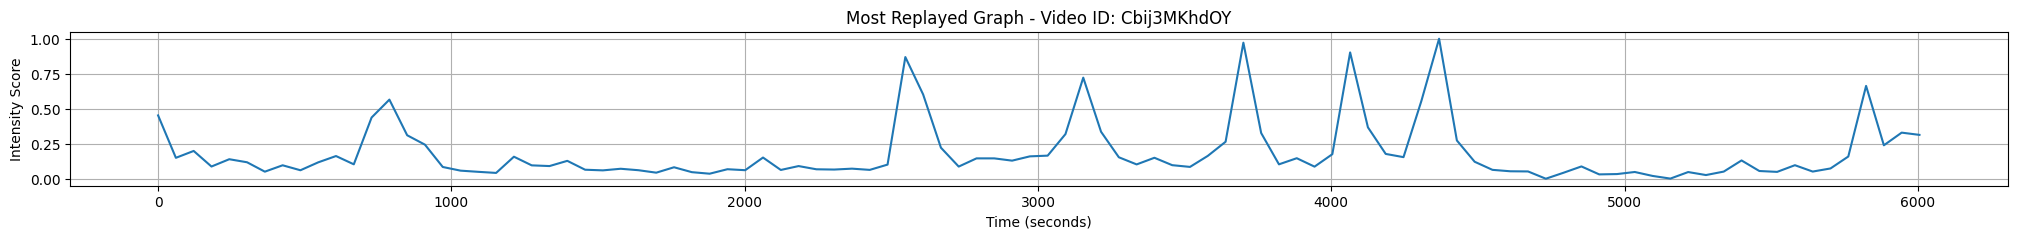

In [7]:


markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


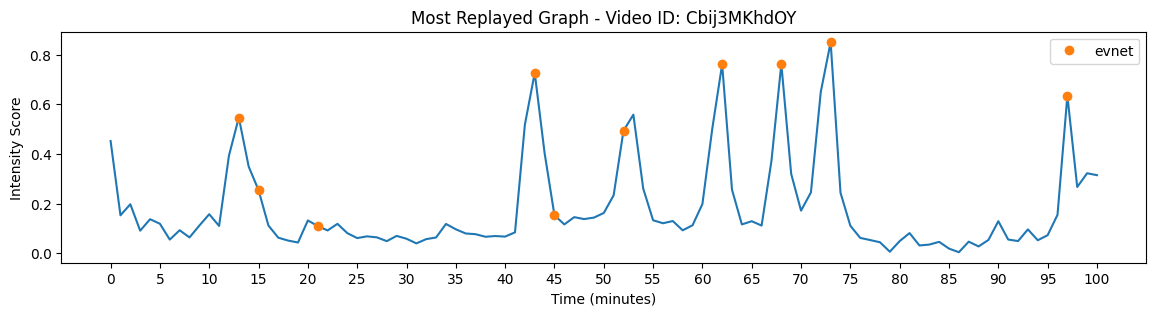

In [8]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# qms 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
total_duration_minutes = total_duration_seconds / 60
new_time = np.arange(0, total_duration_minutes, 1) * 60
# new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
# peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(14, 3))
plt.plot(new_time / 60, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(np.array(event_lst) , smoothed_intensity_scores[event_lst], "o", label='evnet')
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
# plt.grid(True)
plt.xticks(np.arange(0, total_duration_minutes + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.legend()
plt.show()

# 소리 크기

In [9]:
from moviepy.editor import VideoFileClip
import librosa
import numpy as np
import matplotlib.pyplot as plt

# # 비디오 파일 경로
# video_path = "C:/Users/vml_sub/Documents/Minsun2024/highlight/source/Cbij3MKhdOY.mp4"

# # 비디오에서 오디오 추출
# video = VideoFileClip(video_path)
# audio = video.audio
# audio.write_audiofile("temp_audio.wav")



# 임시 오디오 파일 삭제
import os
# os.remove("temp_audio.wav")

In [10]:
# 오디오 파일 로드
# y, sr = librosa.load("soccer.wav")
y, sr = librosa.load("combined_output_accom.wav")

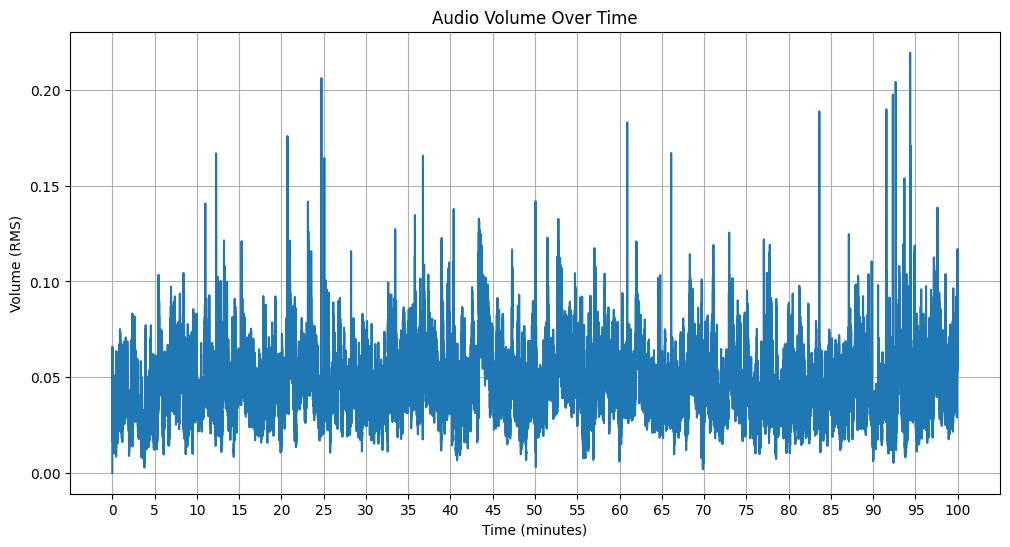

In [11]:


# 소리 크기(RMS) 계산
frame_length = int(sr * 0.05)  # 50ms 프레임
hop_length = int(sr * 0.025)  # 25ms 홉
rms = librosa.feature.rms(y=y, frame_length=frame_length, hop_length=hop_length)
rms = rms.squeeze()  # 2D에서 1D로 변환

# 시간 배열 생성 (분 단위)
times = librosa.times_like(rms, sr=sr, hop_length=hop_length) / 60

# 그래프 그리기
plt.figure(figsize=(12, 6))
plt.plot(times, rms)
plt.title("Audio Volume Over Time")
plt.xlabel("Time (minutes)")
plt.ylabel("Volume (RMS)")
plt.grid(True)

# x축 눈금 설정 (5분 간격)
max_time = times[-1]
plt.xticks(np.arange(0, max_time + 5, 5))

plt.show()

# Moving average

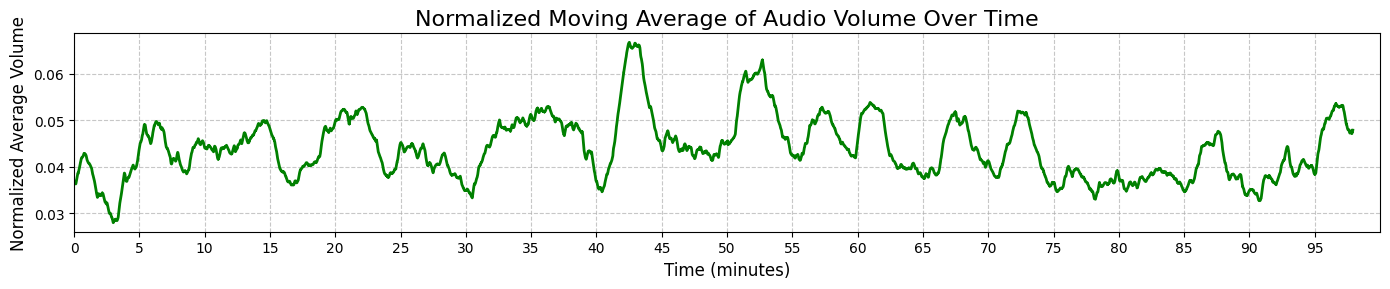

In [12]:
import numpy as np
import matplotlib.pyplot as plt

def moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size), 'valid') / window_size

def normalize(data):
    return (data - np.min(data)) / (np.max(data) - np.min(data))

window_size = 5000  # 조절 가능
ma_rms = moving_average(rms, window_size)

# 0과 1 사이로 정규화

# 결과를 완전히 왼쪽으로 이동
ma_times = times[:len(ma_rms)]

plt.figure(figsize=(14, 3))
plt.plot(ma_times, ma_rms, color='green', linewidth=2)
plt.title("Normalized Moving Average of Audio Volume Over Time", fontsize=16)
plt.xlabel("Time (minutes)", fontsize=12)
plt.ylabel("Normalized Average Volume", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(0, max_time + 5, 5))
# plt.ylim(0, 1)  # y축 범위를 0에서 1로 설정
plt.xlim(0, max_time)  # x축 범위를 0부터 max_time까지로 설정
plt.tight_layout()
plt.show()

In [13]:
def crop_data(times, data, start_time, end_time):
    mask = (times >= start_time) & (times <= end_time)
    return times[mask], data[mask]

In [14]:
start_time = 40  # 시작 시간 (분)
end_time = 97    # 종료 시간 (분)

# Most Replayed 데이터 크롭
new_time_cropped, scores_cropped = crop_data(new_time / 60, smoothed_intensity_scores, start_time, end_time)

# Moving Average 데이터 크롭
ma_times_cropped, ma_rms_cropped = crop_data(ma_times, ma_rms, start_time, end_time)



In [17]:
normalize_scores = normalize(smoothed_intensity_scores)
normalize_ma_rms = normalize(ma_rms)

In [16]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times_cropped, normalize_ma_rms_cropped, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time_cropped, normalize_scores_cropped, color='blue', linewidth=2, label='Most Replayed')


plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id} (40-97 min)', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(start_time, end_time + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.xlim(start_time, end_time)  # x축 범위 설정
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'normalize_ma_rms_cropped' is not defined

<Figure size 1400x300 with 0 Axes>

In [ ]:
def crop_data(times, data, start_time, end_time):
    mask = (times >= start_time) & (times <= end_time)
    return times[mask], data[mask]

In [ ]:
start_time = 40  # 시작 시간 (분)
end_time = 97    # 종료 시간 (분)

# Most Replayed 데이터 크롭
new_time_cropped, scores_cropped = crop_data(new_time / 60, smoothed_intensity_scores, start_time, end_time)

# Moving Average 데이터 크롭
ma_times_cropped, ma_rms_cropped = crop_data(ma_times, ma_rms, start_time, end_time)



In [ ]:
normalize_scores_cropped = normalize(scores_cropped)
normalize_ma_rms_cropped = normalize(ma_rms_cropped)

In [18]:
plt.figure(figsize=(14, 3))

# 오디오 볼륨 그래프
plt.plot(ma_times_cropped, normalize_ma_rms_cropped, color='green', linewidth=2, label='Audio Volume')

# Most Replayed 그래프
plt.plot(new_time_cropped, normalize_scores_cropped, color='blue', linewidth=2, label='Most Replayed')


plt.title(f'Audio Volume and Most Replayed Graph - Video ID: {video_id} (40-97 min)', fontsize=16)
plt.xlabel('Time (minutes)', fontsize=12)
plt.ylabel('Normalized Score', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(np.arange(start_time, end_time + 1, 5))  # 5분 간격으로 x축 눈금 표시
plt.xlim(start_time, end_time)  # x축 범위 설정
plt.legend()
plt.tight_layout()
plt.show()

NameError: name 'normalize_ma_rms_cropped' is not defined

<Figure size 1400x300 with 0 Axes>

Pearson 상관계수: 0.36759263752788957
P-value: 0.00015584323882611458


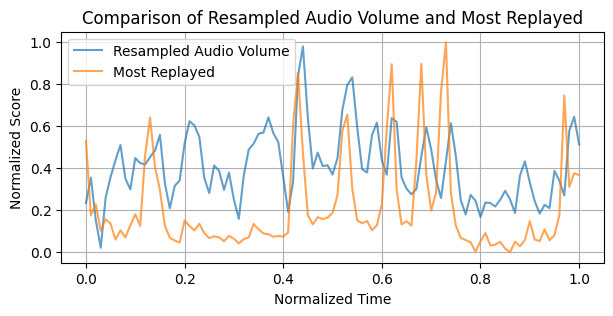

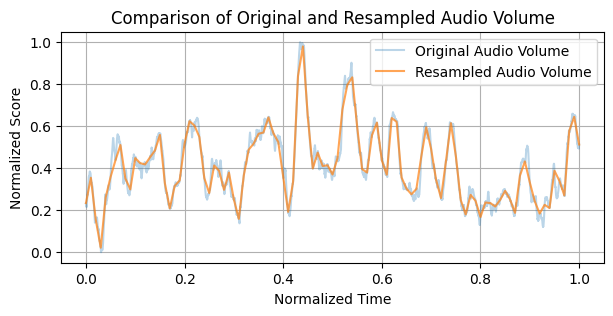

In [19]:
import numpy as np
from scipy import interpolate, stats
import matplotlib.pyplot as plt

# 리샘플링 함수
def resample(x, y, num_points):
    f = interpolate.interp1d(x, y, kind='linear', fill_value='extrapolate')
    x_new = np.linspace(x.min(), x.max(), num_points)
    y_new = f(x_new)
    return x_new, y_new

# 원본 데이터의 x 축 (시간) 생성
x_ma_rms = np.linspace(0, 1, len(normalize_ma_rms))
x_scores = np.linspace(0, 1, len(normalize_scores))

# normalize_ma_rms를 normalize_scores의 길이에 맞춰 리샘플링
x_resampled, y_resampled = resample(x_ma_rms, normalize_ma_rms, len(normalize_scores))

# Pearson 상관계수 계산
correlation, p_value = stats.pearsonr(y_resampled, normalize_scores)

print(f"Pearson 상관계수: {correlation}")
print(f"P-value: {p_value}")

# 시각화
plt.figure(figsize=(7, 3))
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.plot(x_scores, normalize_scores, label='Most Replayed', alpha=0.7)
plt.title('Comparison of Resampled Audio Volume and Most Replayed')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

# 원본 데이터와 리샘플링된 데이터 비교 (선택적)
plt.figure(figsize=(7, 3))
plt.plot(x_ma_rms, normalize_ma_rms, label='Original Audio Volume', alpha=0.3)
plt.plot(x_resampled, y_resampled, label='Resampled Audio Volume', alpha=0.7)
plt.title('Comparison of Original and Resampled Audio Volume')
plt.xlabel('Normalized Time')
plt.ylabel('Normalized Score')
plt.legend()
plt.grid(True)
plt.show()

In [21]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim = cosine_similarity(y_resampled.reshape(1, -1), normalize_scores.reshape(1, -1))[0][0]
print(f"Cosine Similarity: {cos_sim}")

Cosine Similarity: 0.7394270230551546
